# Praktikum Analisis Sentimen: Kebakaran Hutan dan Lahan (Karhutla)
Neural Network (MLP) + TF-IDF. Notebook ini mencakup Langkah 1 sampai 8. Langkah 2 dan 9 (dashboard dan prediksi teks baru) ada di file `app_sentimen_nn.py`.

## Langkah 1: Pengambilan Data
Data hasil crawling tersimpan di file Excel. Sel di bawah mengubahnya menjadi `tweet_data.csv` dengan kolom `created_at`, `username`, dan `full_text`.

In [3]:
import pandas as pd

# Use r"" for the path string and openpyxl for .xlsx files
file_path = r"D:\Analisis Big Data Ardian\Praktikum Analisis sentimen menggunakan Neural Network\DataScrapping.xlsx"

df_raw = pd.read_excel(file_path, engine="openpyxl")
df_raw[["created_at", "username", "full_text"]].to_csv("tweet_data.csv", index=False, encoding="utf-8")

df = pd.read_csv("tweet_data.csv")
df = df.dropna(subset=["full_text"]).drop_duplicates(subset="full_text").reset_index(drop=True)
print("Jumlah tweet:", len(df))
df.head()

Jumlah tweet: 767


,created_at,username,full_text
0,2026-11-15T00:40:42.000Z,PocongGaib,"DISINDIR KOK GA KERASA SIH, GOBLOK.\n\nSi Leo ..."
1,2026-11-02T23:43:32.000Z,SalingJagaWarga,"WARGA, TOLONG LIHAT PAPUA!\nSejak 30 Oktober 2..."
2,2026-11-16T02:21:51.000Z,tribunnews,Presiden Republik Indonesia Prabowo Subianto m...
3,2026-11-12T09:53:11.000Z,LuckyLaki24,319 ribu hektare hutan dan lahan di Papua Sela...
4,2026-11-16T03:42:26.000Z,jaringnusa,"sepanjang 2026, kebakaran hutan dan lahan di I..."


## Langkah 3: Pemrosesan Teks
Menghapus URL, mention, hashtag, simbol, dan angka; case folding; merapikan spasi. Hasilnya disimpan di kolom `clean_text`.

In [4]:
import re

def bersihkan_teks(teks):
    teks = str(teks).lower()                       # case folding
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)  # URL
    teks = re.sub(r"@\w+", " ", teks)              # mention
    teks = re.sub(r"#\w+", " ", teks)              # hashtag
    teks = re.sub(r"[^a-z\s]", " ", teks)          # simbol & angka
    return re.sub(r"\s+", " ", teks).strip()       # spasi berlebih

df["clean_text"] = df["full_text"].apply(bersihkan_teks)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
df[["full_text", "clean_text"]].head(10)

,full_text,clean_text
0,"DISINDIR KOK GA KERASA SIH, GOBLOK.\n\nSi Leo ...",disindir kok ga kerasa sih goblok si leo kagak...
1,"WARGA, TOLONG LIHAT PAPUA!\nSejak 30 Oktober 2...",warga tolong lihat papua sejak oktober kebakar...
2,Presiden Republik Indonesia Prabowo Subianto m...,presiden republik indonesia prabowo subianto m...
3,319 ribu hektare hutan dan lahan di Papua Sela...,ribu hektare hutan dan lahan di papua selatan ...
4,"sepanjang 2026, kebakaran hutan dan lahan di I...",sepanjang kebakaran hutan dan lahan di indones...
5,ALERTA ALERTA ALERTA ⚠️⚠️🚨🚨\n\nKebakaran Hutan...,alerta alerta alerta kebakaran hutan dan lahan...
6,Jangan pakai El Niño atau kemarau sebagai kamb...,jangan pakai el ni o atau kemarau sebagai kamb...
7,Hai guys. Lewat ga? Kalau lewat tolong bantu l...,hai guys lewat ga kalau lewat tolong bantu lik...
8,🚨 15 Personel Gugur Padamkan Karhutla Sepanjan...,personel gugur padamkan karhutla sepanjang mit...
9,"03.12 WITA, 12 NOV 2026.\n\nDESA TELUKBINGKAI,...",wita nov desa telukbingkai kecamatan kenohan k...


## Langkah 4: Pelabelan Sentimen (Rule-Based)
Label ditentukan dari jumlah kata positif dan negatif. Kata dasar topik seperti "karhutla" dan "kebakaran" sengaja tidak dimasukkan ke kamus karena bukan penanda sentimen.

In [5]:
KATA_POSITIF = {
    "aman", "lega", "selamat", "bantuan", "bantu", "membantu", "pulih", "berhasil",
    "sukses", "membaik", "terkendali", "dipadamkan", "padam", "apresiasi", "syukur",
    "bersyukur", "alhamdulillah", "dukung", "mendukung", "siaga", "tangguh", "relawan",
    "peduli", "solusi", "dihentikan", "menghentikan", "teratasi", "harapan", "semangat",
    "optimis", "hujan", "turun", "berkurang", "menurun", "normal", "cegah", "pencegahan",
    "sigap", "tanggap", "cepat", "gotong", "royong", "kolaborasi", "sinergi", "upaya",
    "penghargaan", "santunan", "belasungkawa", "lestari", "pelestarian", "menjaga",
    "edukasi", "sosialisasi", "penyuluhan", "patroli", "terbaik", "hebat", "salut",
    "bangga", "pahlawan", "heroik", "sehat", "damai", "terima", "kasih",
}
KATA_NEGATIF = {
    "parah", "rusak", "bahaya", "berbahaya", "kabut", "asap", "korban", "meninggal",
    "tewas", "gugur", "hangus", "musnah", "kerugian", "rugi", "dampak", "ancam",
    "mengancam", "krisis", "darurat", "sesak", "ispa", "polusi", "tercemar", "gagal",
    "lalai", "sengaja", "dibakar", "pembakaran", "marah", "kecewa", "bencana",
    "terbakar", "menyebar", "kritis", "buruk", "menderita", "gawat", "sedih", "derita",
    "kematian", "korupsi", "jahat", "salah",
}

def beri_label(teks):
    kata = teks.split()
    pos = sum(k in KATA_POSITIF for k in kata)
    neg = sum(k in KATA_NEGATIF for k in kata)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["clean_text"].apply(beri_label)
df[["clean_text", "sentimen"]].head(10)

,clean_text,sentimen
0,disindir kok ga kerasa sih goblok si leo kagak...,netral
1,warga tolong lihat papua sejak oktober kebakar...,netral
2,presiden republik indonesia prabowo subianto m...,netral
3,ribu hektare hutan dan lahan di papua selatan ...,negatif
4,sepanjang kebakaran hutan dan lahan di indones...,netral
5,alerta alerta alerta kebakaran hutan dan lahan...,netral
6,jangan pakai el ni o atau kemarau sebagai kamb...,negatif
7,hai guys lewat ga kalau lewat tolong bantu lik...,netral
8,personel gugur padamkan karhutla sepanjang mit...,negatif
9,wita nov desa telukbingkai kecamatan kenohan k...,netral


## Langkah 5: Analisis Distribusi Sentimen

sentimen
positif    148
netral     436
negatif    183
Name: count, dtype: int64


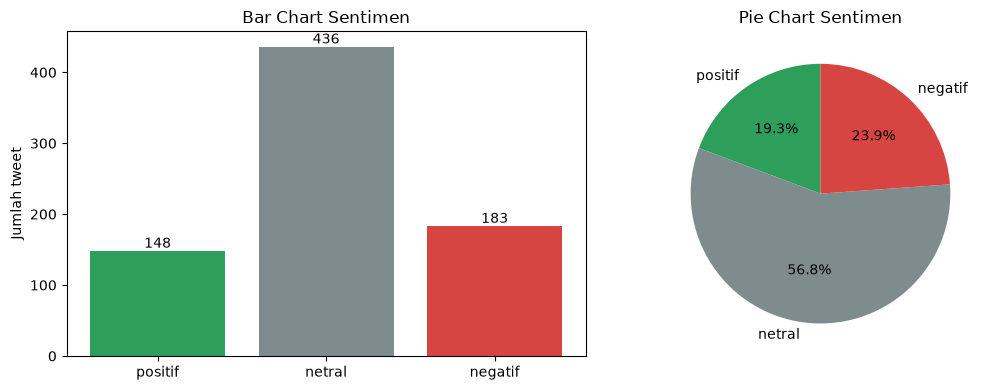

In [6]:
import matplotlib.pyplot as plt

URUTAN = ["positif", "netral", "negatif"]
WARNA_BAR = ["#2e9e5b", "#7f8c8d", "#d64541"]

hitung = df["sentimen"].value_counts().reindex(URUTAN, fill_value=0)
print(hitung)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bars = ax1.bar(hitung.index, hitung.values, color=WARNA_BAR)
ax1.bar_label(bars)
ax1.set_title("Bar Chart Sentimen")
ax1.set_ylabel("Jumlah tweet")
ax2.pie(hitung.values, labels=hitung.index, colors=WARNA_BAR, autopct="%1.1f%%", startangle=90)
ax2.set_title("Pie Chart Sentimen")
plt.tight_layout()
plt.show()

## Langkah 6: Visualisasi WordCloud
Warna dibedakan per sentimen: hijau (positif), biru (netral), merah (negatif).

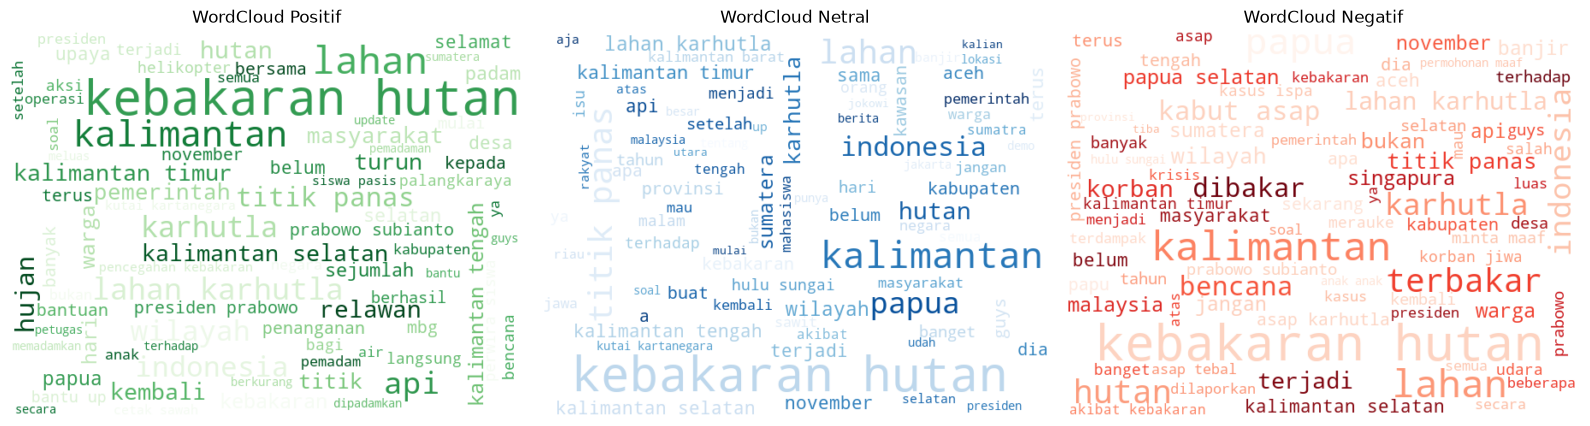

In [7]:
from wordcloud import WordCloud

STOPWORDS = {
    "yang", "di", "dan", "ke", "dari", "ini", "itu", "untuk", "dengan", "pada", "dalam",
    "adalah", "juga", "atau", "akan", "sudah", "telah", "ada", "tidak", "tak", "nggak",
    "ga", "gak", "yg", "dg", "dgn", "sebagai", "oleh", "karena", "agar", "saat", "para",
    "mereka", "kita", "kami", "saya", "aku", "gue", "gw", "kamu", "anda", "nya", "lah",
    "kah", "pun", "si", "sih", "dong", "deh", "kok", "lagi", "masih", "sangat", "lebih",
    "bisa", "dapat", "harus", "jadi", "kalau", "kalo", "jika", "bila", "ketika", "hingga",
    "sampai", "tapi", "tetapi", "namun", "serta", "tersebut", "sebuah", "satu", "dua",
    "the", "of", "to", "and", "in", "is", "for", "on", "co", "https", "amp", "rt",
}
WARNA_WC = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kelas in zip(axes, URUTAN):
    teks_kelas = " ".join(df.loc[df["sentimen"] == kelas, "clean_text"])
    ax.set_title(f"WordCloud {kelas.capitalize()}")
    ax.axis("off")
    if not teks_kelas.strip():
        continue
    wc = WordCloud(width=600, height=450, background_color="white",
                   colormap=WARNA_WC[kelas], stopwords=STOPWORDS, max_words=80).generate(teks_kelas)
    ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

## Langkah 7: Model Neural Network (MLP)
Split data 80:20, TF-IDF, lalu MLP dengan aktivasi ReLU, optimizer Adam, dan 100 neuron tersembunyi.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

vec = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2, stop_words=list(STOPWORDS))
X = vec.fit_transform(df["clean_text"])
y = df["sentimen"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape[0], "| Data uji:", X_test.shape[0])

model = MLPClassifier(hidden_layer_sizes=(100,), activation="relu",
                      solver="adam", max_iter=300, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model selesai dilatih.")

Data latih: 613 | Data uji: 154
Model selesai dilatih.


## Langkah 8: Evaluasi Model

In [9]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

akurasi = accuracy_score(y_test, y_pred)
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=URUTAN, zero_division=0)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)

print(f"Akurasi          : {akurasi:.2%}")
print(f"Presisi (macro)  : {p_m:.2%}")
print(f"Recall (macro)   : {r_m:.2%}")
print(f"F1-Score (macro) : {f_m:.2%}")

tabel = pd.DataFrame({"Presisi": p, "Recall": r, "F1-Score": f, "Support": s}, index=URUTAN)
display(tabel.round(2))
print(classification_report(y_test, y_pred, labels=URUTAN, zero_division=0))

Akurasi          : 70.78%
Presisi (macro)  : 70.33%
Recall (macro)   : 62.63%
F1-Score (macro) : 64.49%


,Presisi,Recall,F1-Score,Support
positif,0.64,0.60,0.62,30
netral,0.72,0.87,0.79,87
negatif,0.75,0.41,0.53,37


              precision    recall  f1-score   support

     positif       0.64      0.60      0.62        30
      netral       0.72      0.87      0.79        87
     negatif       0.75      0.41      0.53        37

    accuracy                           0.71       154
   macro avg       0.70      0.63      0.64       154
weighted avg       0.71      0.71      0.69       154



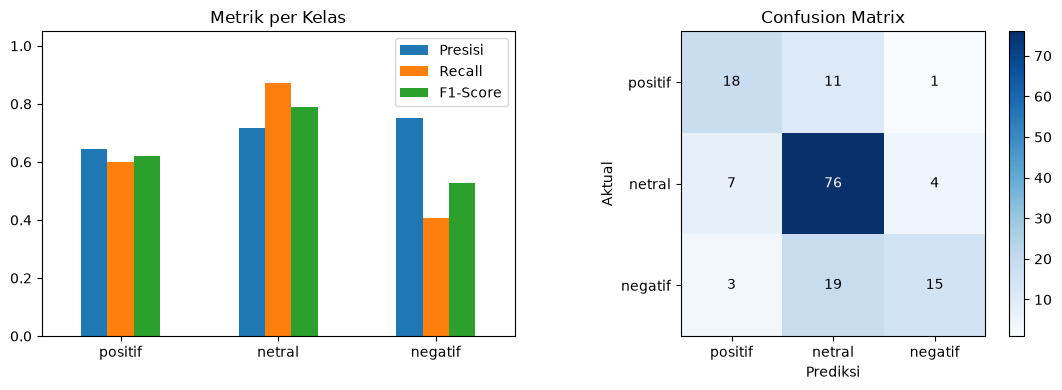

In [10]:
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
tabel[["Presisi", "Recall", "F1-Score"]].plot(kind="bar", ax=ax1, rot=0)
ax1.set_ylim(0, 1.05)
ax1.set_title("Metrik per Kelas")

cm = confusion_matrix(y_test, y_pred, labels=URUTAN)
im = ax2.imshow(cm, cmap="Blues")
ax2.set_xticks(range(3), URUTAN)
ax2.set_yticks(range(3), URUTAN)
ax2.set_xlabel("Prediksi")
ax2.set_ylabel("Aktual")
ax2.set_title("Confusion Matrix")
for i in range(3):
    for j in range(3):
        ax2.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax2)
plt.tight_layout()
plt.show()

## Uji cepat prediksi teks baru
Versi dashboard interaktifnya ada di `app_sentimen_nn.py` (Langkah 9).

In [11]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi(teks):
    bersih = bersihkan_teks(teks)
    proba = model.predict_proba(vec.transform([bersih]))[0]
    kelas = model.classes_[proba.argmax()]
    print(f"{EMOJI[kelas]} {kelas.upper()}")
    for k, pr in zip(model.classes_, proba):
        print(f"  {k}: {pr:.2%}")

prediksi("Kabut asap akibat karhutla makin parah, warga sesak napas")
prediksi("Alhamdulillah api berhasil dipadamkan berkat bantuan relawan")

😠 NEGATIF
  negatif: 98.45%
  netral: 0.80%
  positif: 0.76%
😊 POSITIF
  negatif: 0.10%
  netral: 0.14%
  positif: 99.76%
